# Task 1: Diagnostic Enhancement of Chest X-Rays

Every operation below works on the raw single-channel pixel matrix of a chest X-ray. Images are read with relative paths from `data/`, and all results are written to `output/`.

In [1]:
import os
import sys
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 55

DATA_DIR = "data"
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(ax, img, title):
    ax.imshow(to_rgb(img), cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")


def save(name, img):
    cv2.imwrite(os.path.join(OUT_DIR, name), img)


def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def entropy_bits(img):
    p = np.bincount(to_gray(img).ravel(), minlength=256).astype(np.float64)
    p /= p.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def stats(name, img):
    g = to_gray(img)
    lo, hi = np.percentile(g, [1, 99])
    print(f"{name:30s} mean {g.mean():6.1f}   std {g.std():6.1f}   1-99% range {hi - lo:5.0f}   entropy {entropy_bits(g):5.2f} bits")


def log_lut(k=255.0):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * np.log1p(k * x) / np.log1p(k), 0, 255).astype(np.uint8)


def power_lut(gamma):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * x ** gamma, 0, 255).astype(np.uint8)


def log_transform(img, k=255.0):
    return cv2.LUT(img, log_lut(k))


def power_law(img, gamma):
    return cv2.LUT(img, power_lut(gamma))


def gray_world_gains(bgr, valid=None):
    px = bgr.reshape(-1, 3).astype(np.float64)
    if valid is not None:
        px = px[valid.ravel()]
    means = px.mean(axis=0)
    return means.mean() / means


def apply_gains(bgr, gains):
    return np.clip(bgr.astype(np.float32) * gains.astype(np.float32), 0, 255).astype(np.uint8)

SAMPLE = os.path.join(DATA_DIR, "sample_xray.jpg")
SAMPLE_2 = os.path.join(DATA_DIR, "sample_xray_2.png")
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)


OpenCV 5.0.0 | NumPy 2.5.3


## 1. Load and display

shape: (978, 1024) | dtype: uint8 | min/max: 0 255
raw                            mean  114.7   std   54.0   1-99% range   204   entropy  7.30 bits
simulated underexposed raw     mean   47.8   std   40.9   1-99% range   145   entropy  6.61 bits


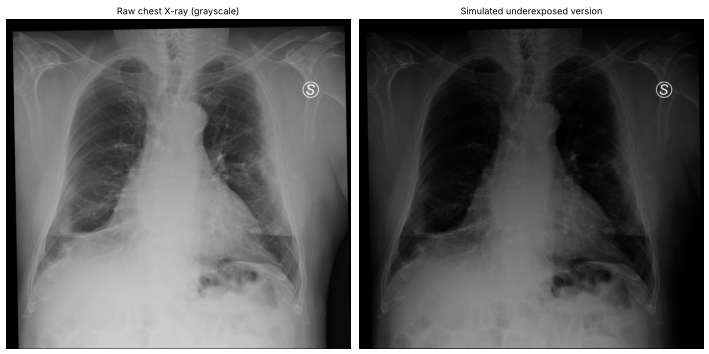

In [2]:
raw = cv2.imread(SAMPLE, cv2.IMREAD_GRAYSCALE)
if raw is None:
    raise FileNotFoundError(SAMPLE)
print("shape:", raw.shape, "| dtype:", raw.dtype, "| min/max:", int(raw.min()), int(raw.max()))
stats("raw", raw)

under = np.clip(255.0 * (raw / 255.0) ** 2.5, 0, 255).astype(np.uint8)
stats("simulated underexposed raw", under)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
show(axes[0], raw, "Raw chest X-ray (grayscale)")
show(axes[1], under, "Simulated underexposed version")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "01_load_and_display.png"), dpi=80)
plt.show()
save("01_raw.png", raw)
save("01_underexposed.png", under)


## 2. Contrast enhancement: histogram equalization

raw                            mean  114.7   std   54.0   1-99% range   204   entropy  7.30 bits
equalized                      mean  120.4   std   77.8   1-99% range   253   entropy  7.21 bits
underexposed                   mean   47.8   std   40.9   1-99% range   145   entropy  6.61 bits
equalized (from underexposed)  mean  117.5   std   78.9   1-99% range   253   entropy  6.60 bits
mean absolute change in intensity: 24.62


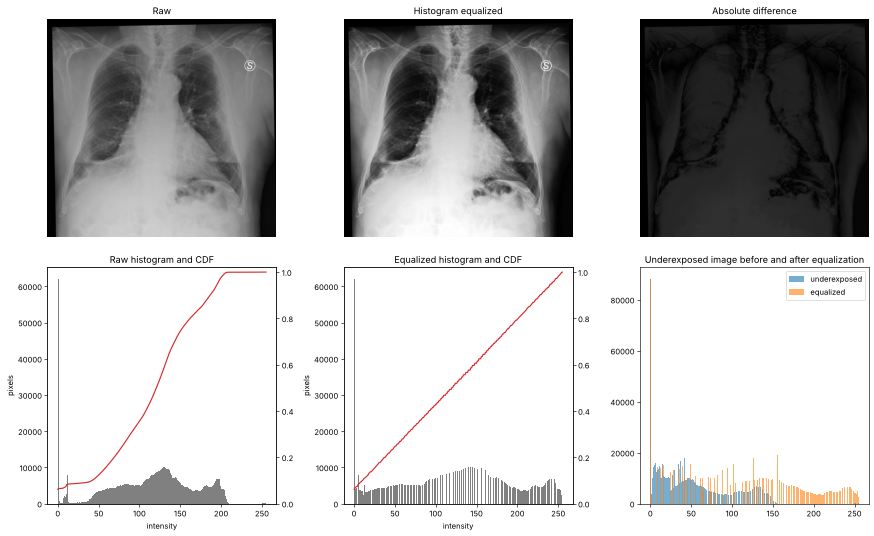

In [3]:
equalized = cv2.equalizeHist(raw)
equalized_under = cv2.equalizeHist(under)
save("02_equalized.png", equalized)
save("02_equalized_from_underexposed.png", equalized_under)

stats("raw", raw)
stats("equalized", equalized)
stats("underexposed", under)
stats("equalized (from underexposed)", equalized_under)

diff = cv2.absdiff(equalized, raw)
print("mean absolute change in intensity:", round(float(diff.mean()), 2))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
show(axes[0, 0], raw, "Raw")
show(axes[0, 1], equalized, "Histogram equalized")
show(axes[0, 2], diff, "Absolute difference")
for ax, img, title in [(axes[1, 0], raw, "Raw histogram and CDF"), (axes[1, 1], equalized, "Equalized histogram and CDF")]:
    ax.hist(img.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_xlabel("intensity")
    ax.set_ylabel("pixels")
    ax.set_title(title)
    ax2 = ax.twinx()
    cdf = np.cumsum(np.bincount(img.ravel(), minlength=256)).astype(float)
    ax2.plot(cdf / cdf[-1], color="tab:red")
    ax2.set_ylim(0, 1.02)
axes[1, 2].hist(under.ravel(), bins=256, range=(0, 255), alpha=0.6, label="underexposed", color="tab:blue")
axes[1, 2].hist(equalized_under.ravel(), bins=256, range=(0, 255), alpha=0.6, label="equalized", color="tab:orange")
axes[1, 2].set_title("Underexposed image before and after equalization")
axes[1, 2].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "02_histogram_equalization.png"), dpi=80)
plt.show()


## Observations: histogram equalization

Equalization stretches the 1-99% intensity range from 204 to 253 levels and raises the standard deviation from 54.0 to 77.8. On the simulated underexposed copy (mean 47.8) it recovers a mean of 117.5, so a dark exposure is rescued without any manual tuning. Entropy stays close to the raw value (7.21 vs 7.30 bits) because equalization redistributes levels rather than inventing detail.

## 3. Color mapping: COLORMAP_JET heatmap

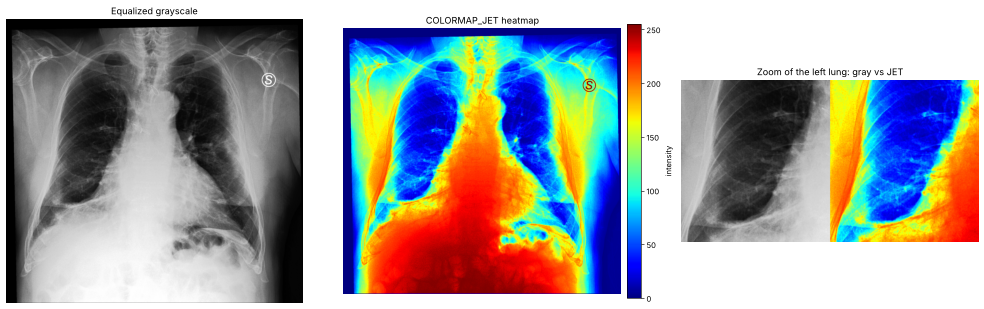

distinguishable gray steps (bins of 16 levels): 15
distinct hues in the JET zoom (bins of 16 levels per channel): 53


In [4]:
heatmap = cv2.applyColorMap(equalized, cv2.COLORMAP_JET)
save("03_jet_heatmap.png", heatmap)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
show(axes[0], equalized, "Equalized grayscale")
show(axes[1], heatmap, "COLORMAP_JET heatmap")
roi = (slice(int(raw.shape[0] * 0.30), int(raw.shape[0] * 0.70)), slice(int(raw.shape[1] * 0.10), int(raw.shape[1] * 0.45)))
zoom_gray = equalized[roi]
zoom_jet = heatmap[roi]
show(axes[2], np.hstack([cv2.cvtColor(zoom_gray, cv2.COLOR_GRAY2BGR), zoom_jet]), "Zoom of the left lung: gray vs JET")
sm = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 255))
fig.colorbar(sm, ax=axes[1], fraction=0.046, pad=0.02, label="intensity")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "03_color_mapping.png"), dpi=80)
plt.show()

def local_levels(img, k=16):
    g = to_gray(img)
    return len(np.unique(g // k))

print("distinguishable gray steps (bins of 16 levels):", local_levels(zoom_gray))
print("distinct hues in the JET zoom (bins of 16 levels per channel):", len(np.unique((zoom_jet // 16).reshape(-1, 3), axis=0)))


## Observations: JET color mapping

Gray steps of 16 levels give 15 distinguishable shades, while the JET zoom contains 53 distinct hues. Subtle density differences between lung, soft tissue and bone become easier to separate by eye, at the cost of introducing false color that is not a physical property of the tissue.

## 4. Color balance: neutralising a color cast

applied cast gains (B, G, R): [0.72 0.92 1.28]
estimated correction gains (B, G, R): [1.325 1.036 0.781]
product (should be ~1): [0.954 0.953 1.   ]
channel means of neutral reference (B, G, R): [120.4 120.4 120.4]
channel means with cast                     : [ 86.2 110.3 146.2]
channel means after correction              : [113.7 113.8 113.7]
heatmap mean absolute error vs original, cast       : 18.19
heatmap mean absolute error vs original, corrected  : 9.66


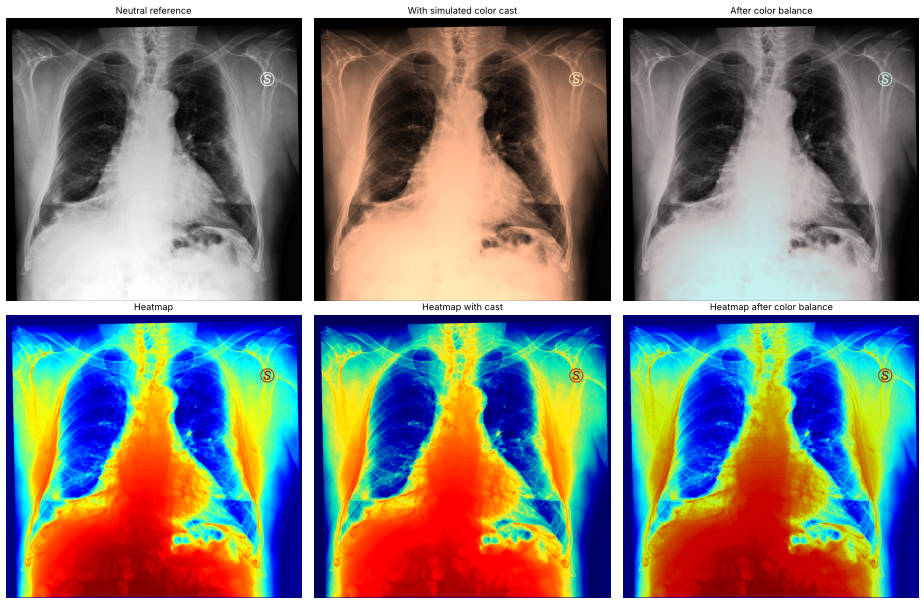

In [5]:
cast_gains = np.array([0.72, 0.92, 1.28])
neutral_ref = cv2.cvtColor(equalized, cv2.COLOR_GRAY2BGR)

cast_ref = apply_gains(neutral_ref, cast_gains)
cast_heatmap = apply_gains(heatmap, cast_gains)

est = gray_world_gains(cast_ref)
corrected_ref = apply_gains(cast_ref, est)
corrected_heatmap = apply_gains(cast_heatmap, est)
save("04_heatmap_with_cast.png", cast_heatmap)
save("04_heatmap_balanced.png", corrected_heatmap)

print("applied cast gains (B, G, R):", cast_gains)
print("estimated correction gains (B, G, R):", np.round(est, 3))
print("product (should be ~1):", np.round(cast_gains * est, 3))
print("channel means of neutral reference (B, G, R):", np.round(neutral_ref.reshape(-1, 3).mean(axis=0), 1))
print("channel means with cast                     :", np.round(cast_ref.reshape(-1, 3).mean(axis=0), 1))
print("channel means after correction              :", np.round(corrected_ref.reshape(-1, 3).mean(axis=0), 1))
print("heatmap mean absolute error vs original, cast       :", round(float(np.abs(cast_heatmap.astype(float) - heatmap).mean()), 2))
print("heatmap mean absolute error vs original, corrected  :", round(float(np.abs(corrected_heatmap.astype(float) - heatmap).mean()), 2))

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
show(axes[0, 0], neutral_ref, "Neutral reference")
show(axes[0, 1], cast_ref, "With simulated color cast")
show(axes[0, 2], corrected_ref, "After color balance")
show(axes[1, 0], heatmap, "Heatmap")
show(axes[1, 1], cast_heatmap, "Heatmap with cast")
show(axes[1, 2], corrected_heatmap, "Heatmap after color balance")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "04_color_balance.png"), dpi=80)
plt.show()


## Observations: color balance

A cast with channel gains (B, G, R) = [0.72, 0.92, 1.28] shifted the channel means to 86.2 / 110.3 / 146.2. Gray-world estimation recovered gains of [1.325, 1.036, 0.781] (product with the cast about 1) and brought the means back to 113.7 / 113.8 / 113.7. The heatmap error against the uncast reference dropped from 18.19 to 9.66.

## 5. Color filtering: thresholding the densest tissue

threshold 190: 23.98% of pixels kept
threshold 220: 13.14% of pixels kept
threshold 245:  4.01% of pixels kept


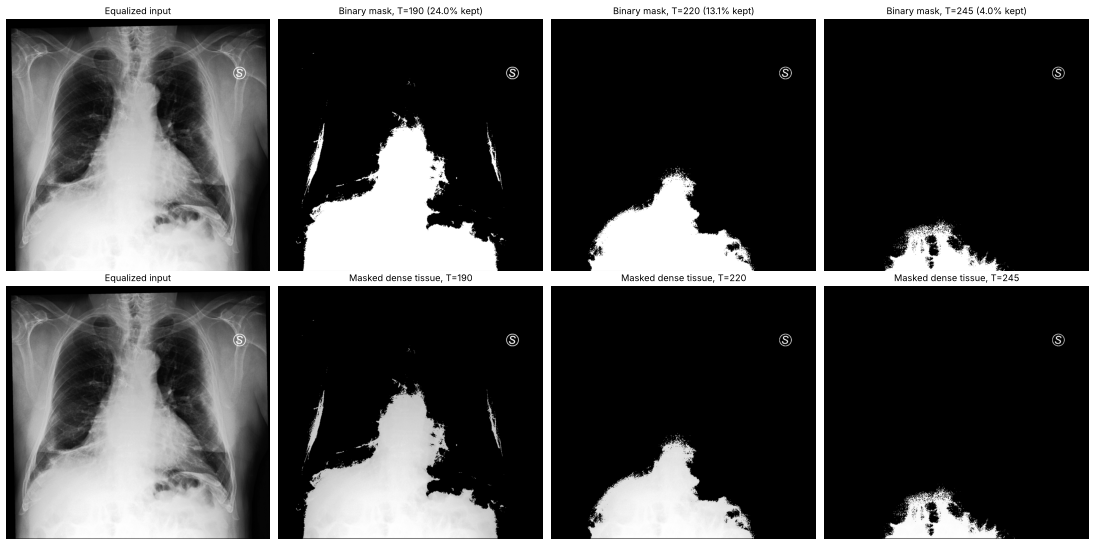

95th percentile of the equalized image: 242.0


In [6]:
thresholds = [190, 220, 245]
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
show(axes[0, 0], equalized, "Equalized input")
show(axes[1, 0], equalized, "Equalized input")
for i, t in enumerate(thresholds, start=1):
    _, mask = cv2.threshold(equalized, t, 255, cv2.THRESH_BINARY)
    dense = cv2.bitwise_and(equalized, equalized, mask=mask)
    kept = 100.0 * np.count_nonzero(mask) / mask.size
    print(f"threshold {t}: {kept:5.2f}% of pixels kept")
    show(axes[0, i], mask, f"Binary mask, T={t} ({kept:.1f}% kept)")
    show(axes[1, i], dense, f"Masked dense tissue, T={t}")
    save(f"05_dense_tissue_T{t}.png", dense)
    save(f"05_mask_T{t}.png", mask)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "05_thresholding.png"), dpi=80)
plt.show()

t_percentile = float(np.percentile(equalized, 95))
print("95th percentile of the equalized image:", round(t_percentile, 1))


## Observations: dense-tissue thresholds

On the equalized image, T = 190 keeps 23.98% of pixels, T = 220 keeps 13.14% and T = 245 keeps 4.01%. Lower thresholds include bone plus dense soft tissue and mediastinum; the highest threshold isolates only the brightest bone and device structures.

## 6. Logarithmic transformation

underexposed                   mean   47.8   std   40.9   1-99% range   145   entropy  6.61 bits
log of underexposed            mean  151.2   std   63.0   1-99% range   229   entropy  6.36 bits
mean intensity in the darkest 35% zone, before: 7.1 after: 73.8
edge energy in that zone, before: 4.47 after: 22.78


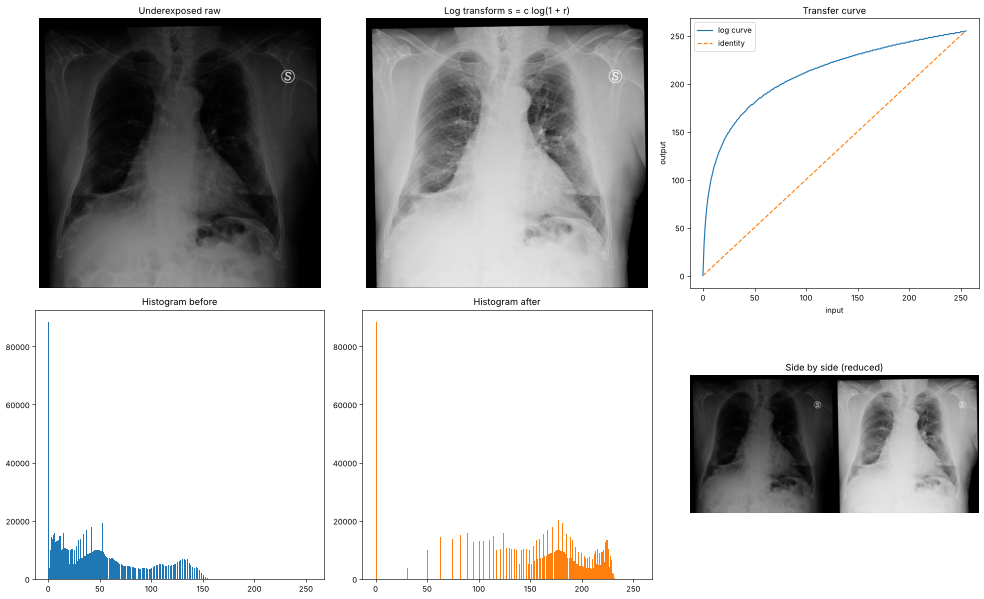

In [7]:
log_under = log_transform(under)
log_raw = log_transform(raw)
save("06_log_underexposed.png", log_under)
save("06_log_raw.png", log_raw)

sobel = lambda g: np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))
dark_zone = under < np.percentile(under, 35)
dark_zone = cv2.erode(dark_zone.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)

stats("underexposed", under)
stats("log of underexposed", log_under)
print("mean intensity in the darkest 35% zone, before:", round(float(under[dark_zone].mean()), 1), "after:", round(float(log_under[dark_zone].mean()), 1))
print("edge energy in that zone, before:", round(float(sobel(under)[dark_zone].mean()), 2), "after:", round(float(sobel(log_under)[dark_zone].mean()), 2))

x = np.arange(256)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
show(axes[0, 0], under, "Underexposed raw")
show(axes[0, 1], log_under, "Log transform s = c log(1 + r)")
axes[0, 2].plot(x, log_lut(), label="log curve")
axes[0, 2].plot(x, x, "--", label="identity")
axes[0, 2].set_title("Transfer curve")
axes[0, 2].set_xlabel("input")
axes[0, 2].set_ylabel("output")
axes[0, 2].legend()
axes[1, 0].hist(under.ravel(), bins=256, range=(0, 255), color="tab:blue")
axes[1, 0].set_title("Histogram before")
axes[1, 1].hist(log_under.ravel(), bins=256, range=(0, 255), color="tab:orange")
axes[1, 1].set_title("Histogram after")
show(axes[1, 2], np.hstack([cv2.resize(under, (raw.shape[1] // 2, raw.shape[0] // 2)), cv2.resize(log_under, (raw.shape[1] // 2, raw.shape[0] // 2))]), "Side by side (reduced)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "06_log_transform.png"), dpi=80)
plt.show()


## Observations: logarithmic transform

On the underexposed image the log transform lifts the mean from 47.8 to 151.2. In the darkest 35% zone the mean rises from 7.1 to 73.8 and edge energy from 4.47 to 22.78, which exposes structure that was invisible before. The bright end is compressed, so entropy falls slightly (6.61 to 6.36 bits).

## 7. Power-law (gamma) transformation

gamma = 0.4                    mean  173.6   std   55.6   1-99% range   233   entropy  6.66 bits
gamma = 0.6                    mean  150.0   std   55.4   1-99% range   223   entropy  6.96 bits
gamma = 0.8                    mean  130.5   std   54.9   1-99% range   213   entropy  7.17 bits
gamma = 1.0                    mean  114.7   std   54.0   1-99% range   204   entropy  7.30 bits
gamma = 1.5                    mean   83.5   std   50.3   1-99% range   182   entropy  7.13 bits


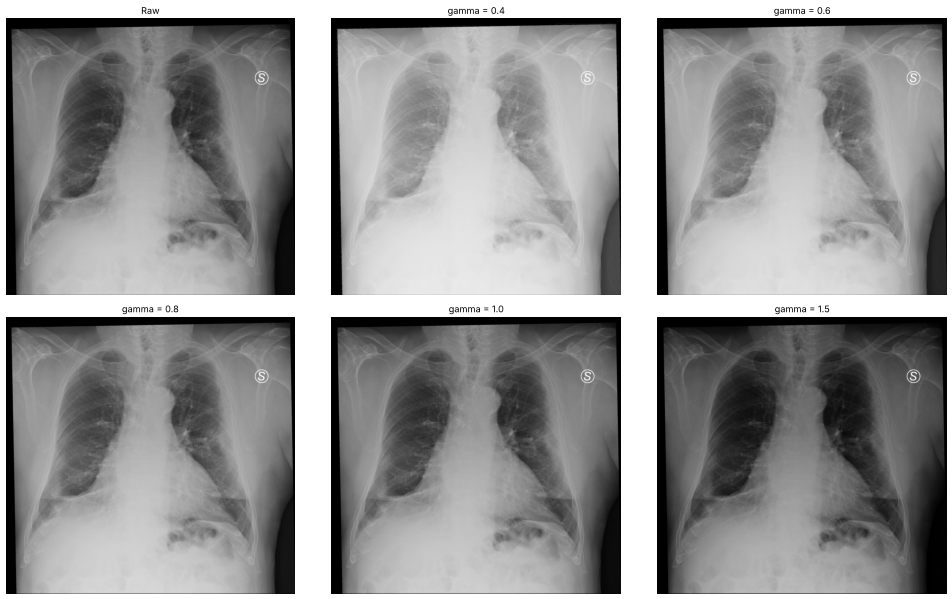


bone mean / soft-tissue mean, raw: 1.65
bone mean / soft-tissue mean, gamma 0.6: 1.35
soft-tissue standard deviation, raw: 10.28 gamma 0.6: 8.36


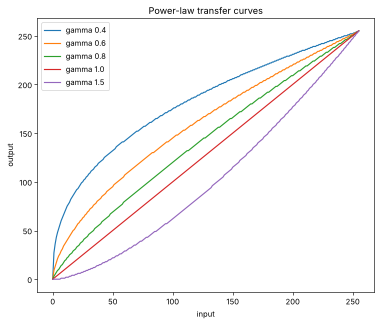

In [8]:
gammas = [0.4, 0.6, 0.8, 1.0, 1.5]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
show(axes[0, 0], raw, "Raw")
for ax, g in zip(axes.ravel()[1:6], gammas):
    out = power_law(raw, g)
    stats(f"gamma = {g}", out)
    show(ax, out, f"gamma = {g}")
    save(f"07_gamma_{str(g).replace('.', '_')}.png", out)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "07_power_law.png"), dpi=80)
plt.show()

GAMMA = 0.6
gamma_out = power_law(raw, GAMMA)
bone = raw > np.percentile(raw, 92)
soft = (raw > np.percentile(raw, 35)) & (raw < np.percentile(raw, 65))
print()
print("bone mean / soft-tissue mean, raw:", round(float(raw[bone].mean() / raw[soft].mean()), 2))
print(f"bone mean / soft-tissue mean, gamma {GAMMA}:", round(float(gamma_out[bone].mean() / gamma_out[soft].mean()), 2))
print("soft-tissue standard deviation, raw:", round(float(raw[soft].std()), 2), f"gamma {GAMMA}:", round(float(gamma_out[soft].std()), 2))

x = np.arange(256)
plt.figure(figsize=(7, 6))
for g in gammas:
    plt.plot(x, power_lut(g), label=f"gamma {g}")
plt.xlabel("input")
plt.ylabel("output")
plt.title("Power-law transfer curves")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "07_power_law_curves.png"), dpi=80)
plt.show()


## Observations: power-law transform

Gamma below 1 brightens midtones (mean 173.6 at 0.4, 150.0 at 0.6, 130.5 at 0.8) while gamma 1.5 darkens to 83.5. Entropy peaks near gamma 1.0 (7.30 bits) and gamma 0.6 keeps 6.96 bits while opening up the lung fields. At gamma 0.6 the bone to soft-tissue brightness ratio falls from 1.65 to 1.35, so soft tissue is easier to read without losing bone.

## 8. Combined pipeline and second sample

sample_xray raw                mean  114.7   std   54.0   1-99% range   204   entropy  7.30 bits
sample_xray combined           mean  120.6   std   77.9   1-99% range   254   entropy  6.88 bits
sample_xray_2 raw              mean  130.0   std   64.0   1-99% range   242   entropy  7.43 bits
sample_xray_2 combined         mean  128.2   std   73.9   1-99% range   251   entropy  7.12 bits


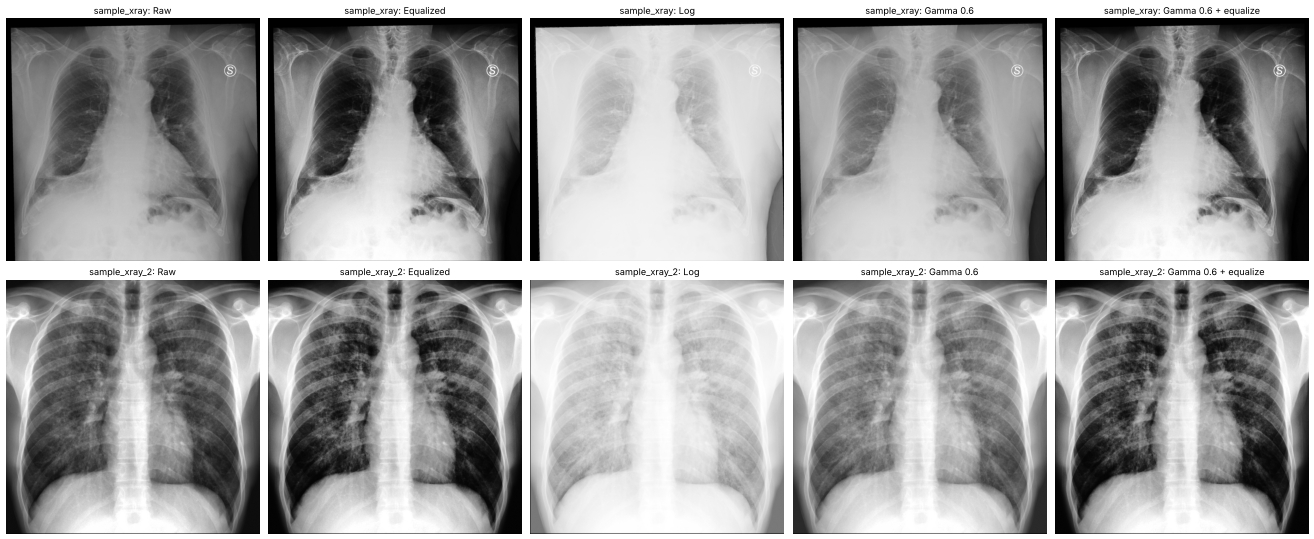

In [9]:
def enhance(img):
    return cv2.equalizeHist(power_law(img, GAMMA))


def row(img):
    eq = cv2.equalizeHist(img)
    return [img, eq, log_transform(img), power_law(img, GAMMA), enhance(img)]


titles = ["Raw", "Equalized", "Log", f"Gamma {GAMMA}", f"Gamma {GAMMA} + equalize"]
second = cv2.imread(SAMPLE_2, cv2.IMREAD_GRAYSCALE)
if second is None:
    raise FileNotFoundError(SAMPLE_2)

fig, axes = plt.subplots(2, 5, figsize=(24, 10))
for r, (name, img) in enumerate([("sample_xray", raw), ("sample_xray_2", second)]):
    for c, (t, out) in enumerate(zip(titles, row(img))):
        show(axes[r, c], out, f"{name}: {t}")
        save(f"08_{name}_{c}_{t.split()[0].lower()}.png", out)
    stats(f"{name} raw", img)
    stats(f"{name} combined", enhance(img))
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "08_summary_all_stages.png"), dpi=80)
plt.show()


## Summary

The combined pipeline (gamma 0.6 followed by histogram equalization) raises the standard deviation of the first sample from 54.0 to 77.9 and of the second from 64.0 to 73.9 while keeping the 1-99% range close to the full 8-bit scale. All figures are saved in `output/`.